In [ ]:
import pandas as pd

df = pd.read_csv("/content/iot_sensor_telemetry .csv")

df.head()

,Timestamp,Sensor_Temp_C,Sensor_Vibration_mm,Sensor_Voltage_V,Catastrophic_Failure
0,2023-01-01 00:00:00,66.490142,1.064301,220.696572,0.0
1,2023-01-01 01:00:00,64.585207,1.138900,220.566647,0.0
2,2023-01-01 02:00:00,66.943066,1.080524,218.126960,0.0
3,2023-01-01 03:00:00,69.569090,1.222084,221.159168,0.0
4,2023-01-01 04:00:00,64.297540,1.439436,217.019835,0.0


In [ ]:
print("Shape of dataset:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

Shape of dataset: (10000, 5)

Column names:
['Timestamp', 'Sensor_Temp_C', 'Sensor_Vibration_mm', 'Sensor_Voltage_V', 'Catastrophic_Failure']

Data types:
Timestamp                object
Sensor_Temp_C           float64
Sensor_Vibration_mm     float64
Sensor_Voltage_V        float64
Catastrophic_Failure    float64
dtype: object

Missing values:
Timestamp               0
Sensor_Temp_C           0
Sensor_Vibration_mm     0
Sensor_Voltage_V        0
Catastrophic_Failure    0
dtype: int64


In [ ]:
df.columns

Index(['Timestamp', 'Sensor_Temp_C', 'Sensor_Vibration_mm', 'Sensor_Voltage_V',
       'Catastrophic_Failure'],
      dtype='object')

In [ ]:
print("First 5 rows:")
display(df.head())

print("\nLast 5 rows:")
display(df.tail())

First 5 rows:


,Timestamp,Sensor_Temp_C,Sensor_Vibration_mm,Sensor_Voltage_V,Catastrophic_Failure
0,2023-01-01 00:00:00,66.490142,1.064301,220.696572,0.0
1,2023-01-01 01:00:00,64.585207,1.138900,220.566647,0.0
2,2023-01-01 02:00:00,66.943066,1.080524,218.126960,0.0
3,2023-01-01 03:00:00,69.569090,1.222084,221.159168,0.0
4,2023-01-01 04:00:00,64.297540,1.439436,217.019835,0.0



Last 5 rows:


,Timestamp,Sensor_Temp_C,Sensor_Vibration_mm,Sensor_Voltage_V,Catastrophic_Failure
9995,2024-02-21 11:00:00,68.903306,1.277565,218.845424,0.0
9996,2024-02-21 12:00:00,59.004965,1.475473,222.889208,0.0
9997,2024-02-21 13:00:00,62.884050,1.275671,218.997265,0.0
9998,2024-02-21 14:00:00,66.487297,1.542706,216.215286,0.0
9999,2024-02-21 15:00:00,66.933165,0.876016,219.542232,0.0


In [ ]:
df['Timestamp'] = pd.to_datetime(df['Timestamp'])

df = df.sort_values('Timestamp').reset_index(drop=True)

df.head()

,Timestamp,Sensor_Temp_C,Sensor_Vibration_mm,Sensor_Voltage_V,Catastrophic_Failure
0,2023-01-01 00:00:00,66.490142,1.064301,220.696572,0.0
1,2023-01-01 01:00:00,64.585207,1.138900,220.566647,0.0
2,2023-01-01 02:00:00,66.943066,1.080524,218.126960,0.0
3,2023-01-01 03:00:00,69.569090,1.222084,221.159168,0.0
4,2023-01-01 04:00:00,64.297540,1.439436,217.019835,0.0


In [ ]:
df['Temperature_Rolling_Mean_12H'] = (
    df['Sensor_Temp_C'].rolling(window=12).mean()
)

df[['Timestamp', 'Sensor_Temp_C', 'Temperature_Rolling_Mean_12H']].head(15)

,Timestamp,Sensor_Temp_C,Temperature_Rolling_Mean_12H
0,2023-01-01 00:00:00,66.490142,NaN
1,2023-01-01 01:00:00,64.585207,NaN
2,2023-01-01 02:00:00,66.943066,NaN
3,2023-01-01 03:00:00,69.569090,NaN
4,2023-01-01 04:00:00,64.297540,NaN
5,2023-01-01 05:00:00,64.297589,NaN
6,2023-01-01 06:00:00,69.737638,NaN
7,2023-01-01 07:00:00,67.302304,NaN
8,2023-01-01 08:00:00,63.591577,NaN
9,2023-01-01 09:00:00,66.627680,NaN


In [ ]:
df['Vibration_Rolling_STD_12H'] = (
    df['Sensor_Vibration_mm'].rolling(window=12).std()
)

df[['Timestamp', 'Sensor_Vibration_mm', 'Vibration_Rolling_STD_12H']].head(15)

,Timestamp,Sensor_Vibration_mm,Vibration_Rolling_STD_12H
0,2023-01-01 00:00:00,1.064301,NaN
1,2023-01-01 01:00:00,1.138900,NaN
2,2023-01-01 02:00:00,1.080524,NaN
3,2023-01-01 03:00:00,1.222084,NaN
4,2023-01-01 04:00:00,1.439436,NaN
5,2023-01-01 05:00:00,1.045792,NaN
6,2023-01-01 06:00:00,1.400164,NaN
7,2023-01-01 07:00:00,1.043666,NaN
8,2023-01-01 08:00:00,1.030475,NaN
9,2023-01-01 09:00:00,1.363719,NaN


In [ ]:
df = df.dropna(
    subset=['Temperature_Rolling_Mean_12H', 'Vibration_Rolling_STD_12H']
).reset_index(drop=True)

print("New shape:", df.shape)

New shape: (9989, 7)


In [ ]:
df['Failure_In_24_Hours'] = df['Catastrophic_Failure'].shift(-24)

df[['Timestamp', 'Catastrophic_Failure', 'Failure_In_24_Hours']].head(30)

,Timestamp,Catastrophic_Failure,Failure_In_24_Hours
0,2023-01-01 11:00:00,0.0,0.0
1,2023-01-01 12:00:00,0.0,0.0
2,2023-01-01 13:00:00,0.0,0.0
3,2023-01-01 14:00:00,0.0,0.0
4,2023-01-01 15:00:00,0.0,0.0
5,2023-01-01 16:00:00,0.0,0.0
6,2023-01-01 17:00:00,0.0,0.0
7,2023-01-01 18:00:00,0.0,0.0
8,2023-01-01 19:00:00,0.0,0.0
9,2023-01-01 20:00:00,0.0,0.0


In [ ]:
# Drop rows with NaN values in the target column caused by shifting
df = df.dropna(subset=['Failure_In_24_Hours']).reset_index(drop=True)
print("New shape after dropping shifted NaNs:", df.shape)

New shape after dropping shifted NaNs: (9965, 8)


In [ ]:
df = df.drop(columns=['Catastrophic_Failure'], errors='ignore')

print("Columns after removing original failure column:")
print(df.columns.tolist())

Columns after removing original failure column:
['Timestamp', 'Sensor_Temp_C', 'Sensor_Vibration_mm', 'Sensor_Voltage_V', 'Temperature_Rolling_Mean_12H', 'Vibration_Rolling_STD_12H', 'Failure_In_24_Hours']


In [ ]:
X = df.drop(columns=['Timestamp', 'Failure_In_24_Hours'])
y = df['Failure_In_24_Hours']

print("Features (X):")
print(X.columns.tolist())

print("\nTarget (y):")
print(y.name)
print("\nNew target length with no NaNs:", len(y))

Features (X):
['Sensor_Temp_C', 'Sensor_Vibration_mm', 'Sensor_Voltage_V', 'Temperature_Rolling_Mean_12H', 'Vibration_Rolling_STD_12H']

Target (y):
Failure_In_24_Hours

New target length with no NaNs: 9965


In [ ]:
split_index = int(len(X) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)
print("Any NaNs in y_test?:", y_test.isnull().any())

Training data: (7972, 5)
Testing data: (1993, 5)
Training target: (7972,)
Testing target: (1993,)
Any NaNs in y_test?: False


In [ ]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=100,
    class_weight='balanced',
    random_state=42
)

print(model)

RandomForestClassifier(class_weight='balanced', random_state=42)


In [ ]:
model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [ ]:
y_pred = model.predict(X_test)

print("Predictions completed successfully!")
print("Number of predictions:", len(y_pred))
print("Matches test target length?:", len(y_pred) == len(y_test))

Predictions completed successfully!
Number of predictions: 1993
Matches test target length?: True


In [ ]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import numpy as np

# Ensure there are no NaNs in either y_test or y_pred before evaluating
valid_mask = ~y_test.isnull() & ~np.isnan(y_pred)
y_test_clean = y_test[valid_mask]
y_pred_clean = y_pred[valid_mask]

accuracy = accuracy_score(y_test_clean, y_pred_clean)

print("Accuracy:", accuracy)

print("\nClassification Report:")
print(classification_report(y_test_clean, y_pred_clean))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_clean, y_pred_clean))

Accuracy: 0.9984947315604616

Classification Report:
              precision    recall  f1-score   support

         0.0       1.00      1.00      1.00      1990
         1.0       0.00      0.00      0.00         3

    accuracy                           1.00      1993
   macro avg       0.50      0.50      0.50      1993
weighted avg       1.00      1.00      1.00      1993


Confusion Matrix:
[[1990    0]
 [   3    0]]


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
feature_importance = model.feature_importances_

feature_names = X_train.columns

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': feature_importance
})

importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

print(importance_df)

                        Feature  Importance
1           Sensor_Vibration_mm    0.385628
0                 Sensor_Temp_C    0.269358
3  Temperature_Rolling_Mean_12H    0.261595
4     Vibration_Rolling_STD_12H    0.050765
2              Sensor_Voltage_V    0.032653


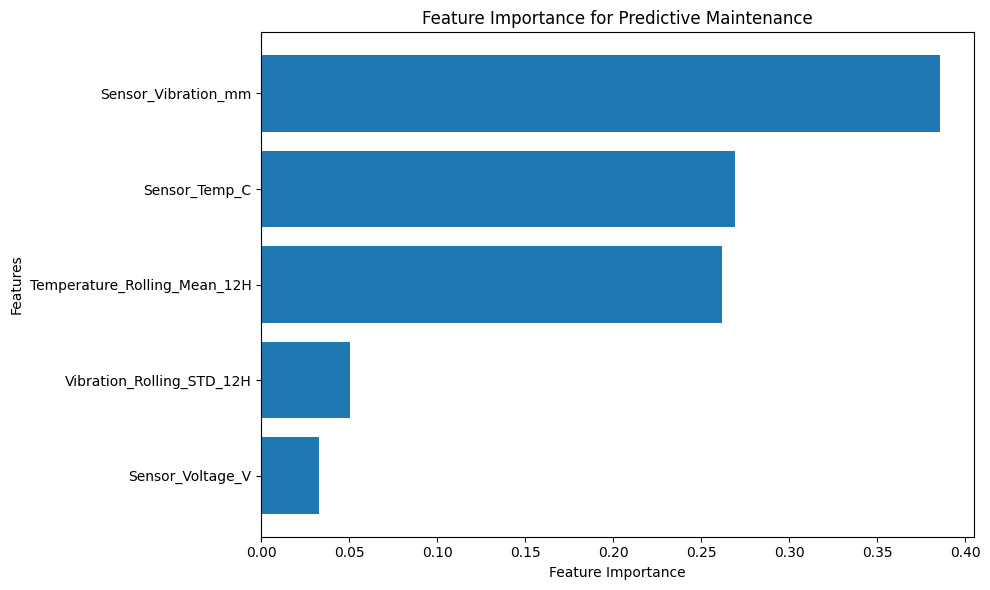

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.barh(
    importance_df['Feature'],
    importance_df['Importance']
)

plt.xlabel('Feature Importance')
plt.ylabel('Features')
plt.title('Feature Importance for Predictive Maintenance')

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [ ]:
top_feature = importance_df.iloc[0]['Feature']
top_importance = importance_df.iloc[0]['Importance']

print("Most important feature:", top_feature)
print("Importance:", top_importance)

Most important feature: Sensor_Vibration_mm
Importance: 0.38562779501803257


In [ ]:
print(f"""
Business Recommendation:

The model identifies {top_feature} as the most important predictive feature
for detecting machine failure 24 hours in advance. The maintenance team
should closely monitor this indicator and investigate abnormal changes
before replacing or servicing the motor. This predictive approach can help
the team move from reactive maintenance to proactive maintenance and reduce
unexpected machine downtime.
""")


Business Recommendation:

The model identifies Sensor_Vibration_mm as the most important predictive feature
for detecting machine failure 24 hours in advance. The maintenance team
should closely monitor this indicator and investigate abnormal changes
before replacing or servicing the motor. This predictive approach can help
the team move from reactive maintenance to proactive maintenance and reduce
unexpected machine downtime.



### Conclusion

The Predictive Maintenance AI project uses IoT sensor telemetry to predict catastrophic machine failure 24 hours in advance. Time-series features such as the 12-hour rolling mean of temperature and 12-hour rolling standard deviation of vibration were engineered to capture changes in machine health. A Random Forest Classifier with balanced class weights was trained using a chronological 80/20 train-test split to prevent data leakage. Model evaluation and feature importance analysis were used to identify important indicators of impending failure and support proactive maintenance decisions. This approach can help the maintenance team detect potential failures earlier and reduce unexpected machine downtime.
